In [2]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})


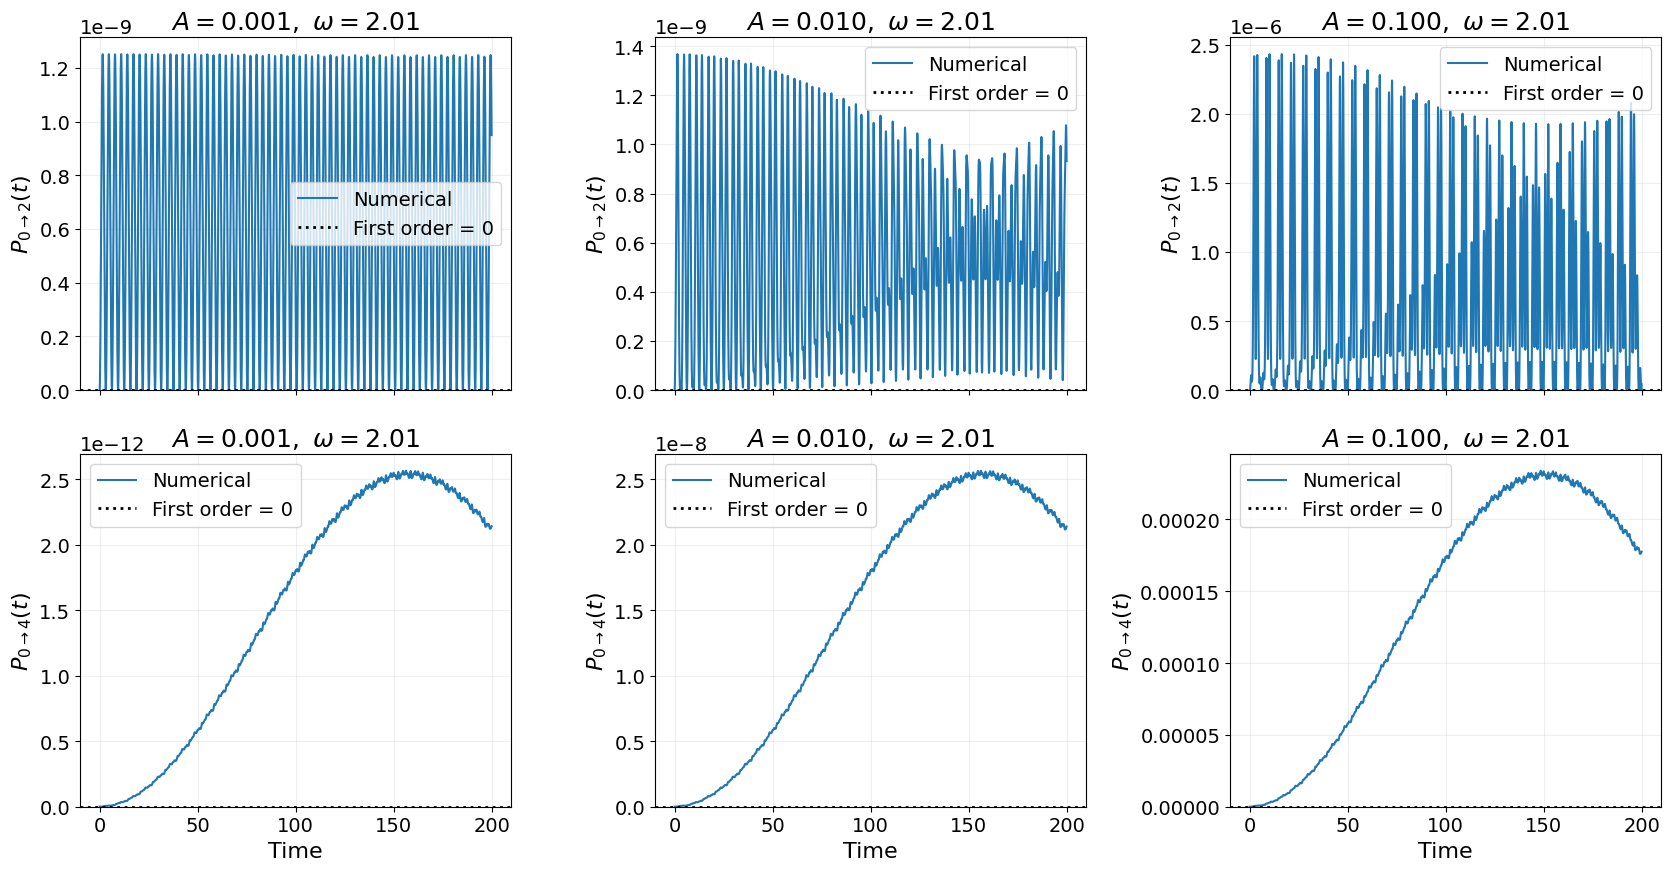

In [3]:
folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

# Parameters
omega = 2.01
A_values = [0.001, 0.01, 0.1]
n = 128
L = 12
dt = 0.02
tmax = 200

ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()

phi0 = basis[:, 0]
phi2 = basis[:, 2]
phi4 = basis[:, 4]

times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

fig, axes = plt.subplots(
    2, 3, figsize=(17, 9), sharex=True
)

for col, A in enumerate(A_values):
    psi = phi0.copy()
    P2 = np.zeros(len(times))
    P4 = np.zeros(len(times))

    for i in range(1, len(times)):
        psi = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=psi,
            t0=times[i - 1]
        )

        P2[i] = np.abs(np.vdot(phi2, psi))**2
        P4[i] = np.abs(np.vdot(phi4, psi))**2

    # Top row: second excited state
    # Bottom row: fourth excited state
    for row, (level, P) in enumerate([(2, P2), (4, P4)]):
        ax = axes[row, col]

        ax.plot(times, P, label="Numerical")
        ax.axhline(
            0, color="black", linestyle=":", linewidth=2,
            label="First order = 0"
        )

        ax.set_title(rf"$A={A:.3f},\ \omega={omega:.2f}$")
        ax.set_ylabel(rf"$P_{{0\to{level}}}(t)$")
        ax.set_ylim(bottom=0)
        ax.legend()
        ax.grid(alpha=0.2)

    axes[1, col].set_xlabel("Time")

plt.tight_layout()
plt.show()

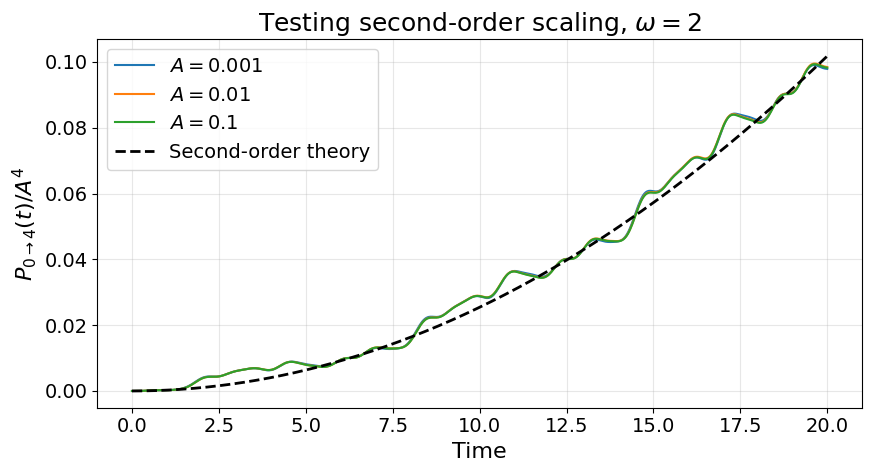

In [4]:
import numpy as np
import matplotlib.pyplot as plt

A_values = [0.001, 0.01, 0.1]
omega = 2.0
tmax = 20

ho = HarmonicOscillator(boundary=(-L, L), n=n)
energies, basis = ho.eigenstates()
phi4 = basis[:, 4]

plt.figure(figsize=(9, 5))

def simulate(A=0.05, omega=1.0, dt=0.02, n=128, L=12, tmax=20, t_eval=None):
    ho = HarmonicOscillator(boundary=(-L, L), n=n)
    x = ho.xi()
    times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

    energies, basis = ho.eigenstates()

    states = np.empty((len(times), n), dtype=complex)
    states[0] = basis[:, 0]

    for i in range(1, len(times)):
        states[i] = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=states[i-1],
            t0=times[i-1]
        )

    amplitudes = states @ basis.conj()
    E0 = np.abs(amplitudes)**2 @ energies

    # Subsample to requested times if t_eval given
    if t_eval is not None:
        indices = [np.argmin(np.abs(times - t)) for t in t_eval]
        return x, times[indices], states[indices], E0[indices]

    return x, times, states, E0

for A in A_values:
    _, t, states, _ = simulate(
        A=A,
        omega=omega,
        n=n,
        L=L,
        dt=0.02,
        tmax=tmax
    )

    P04 = np.abs(states @ phi4.conj())**2

    # Remove the expected A^4 dependence
    plt.plot(
        t, P04 / A**4,
        label=rf"$A={A}$"
    )

# Leading resonant second-order prediction
P_second_scaled = 2.5447e-4 * t**2

plt.plot(
    t,
    P_second_scaled,
    "k--",
    linewidth=2,
    label="Second-order theory"
)

plt.xlabel("Time")
plt.ylabel(r"$P_{0\to4}(t)/A^4$")
plt.title(r"Testing second-order scaling, $\omega=2$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()